# Semantic Topic Mining

In [1]:
import torch
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt

from datasets import load_dataset, concatenate_datasets
from transformers import AutoTokenizer, AutoModel
from sentence_transformers import SentenceTransformer
from sentence_transformers.models import Normalize

from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.cluster import KMeans

/home/xgillard/.venv/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
dataset = load_dataset("arch-be/brabant-xvii", name="doc_by_doc")
dataset = concatenate_datasets([dataset["train"], dataset["test"], dataset["valid"]])
dataset

Dataset({
    features: ['project', 'file_id', 'text'],
    num_rows: 419
})

In [3]:
# On a choisi ce modèle en se basant sur le leaderboard MTEB avec les filtres suivants:
# - il faut que ce soit un modele open source
# - il faut que ce soit un modele qui fasse <= 1B param
# - il faut que le modele performe bien sur la tache STS (semantic text similarity)
# - il faut que le modele supporte bien le néérlandais, francais (et anglais meme si pas utilisé).
#
# Ce modele ci obtient un score moyen de 86% sur la tache STS.
# https://huggingface.co/spaces/mteb/leaderboard
checkpoint = "arch-be/brabant-xvii"
model      = SentenceTransformer(checkpoint, trust_remote_code=True)

## ca c'est juste pour me permettre de facilement travailler avec différents modèles
## sans devoir à chaque fois regarder ce qui est utilisé. Apd maintenant, je suis 
## sur que tous les embeddings seront toujours normalisés.
if not isinstance(model[-1], Normalize):
    model = SentenceTransformer(modules=[*model, Normalize()])

No sentence-transformers model found with name arch-be/brabant-xvii. Creating a new one with mean pooling.


In [4]:
# Le modele nous permet de calculer facilement un embedding pour chacun des textes de notre dataset.
# Si on regarde d'un peu plus près, on voit que le sentence transformer est composé de 3 choses:
# 1. un transformer
# 2. une couche de pooling
# 3. une couche de normalisation (optionnelle)
# **************************************************************************************************
# ATTENTION: vu que la taille de la fenetre de contexte est 512 tokens, il va falloir qu'on découpe
#            les textes en blocs de 512 tokens, sinon on va perdre de l'information.
# **************************************************************************************************
model

SentenceTransformer(
  (0): Transformer({'max_seq_length': 512, 'do_lower_case': False}) with Transformer model: BertModel 
  (1): Pooling({'word_embedding_dimension': 768, 'pooling_mode_cls_token': False, 'pooling_mode_mean_tokens': True, 'pooling_mode_max_tokens': False, 'pooling_mode_mean_sqrt_len_tokens': False, 'pooling_mode_weightedmean_tokens': False, 'pooling_mode_lasttoken': False, 'include_prompt': True})
  (2): Normalize()
)

In [5]:
# On va maintenant regarder le transformer (1e couche) d'un peu plus près. Et tant qu'on y est,
# on va aussi charger le tokenizer vu qu'on va l'utiliser pour découper les textes en blocs de
# 512 tokens (disons plutot en blocs de 510 tokens histoire de pouvoir s'accomoder des tokens
# spéciaux qui sont ajoutés).
#
# En regardant l'appercu du modele, on voit qu'il y a trois blocs
# 1. **Un bloc d'embedding** dont le role est de convertir la suite des token_ids+attention_mask en entrée
#    pour en faire une séquence de vecteurs de taille 'hidden' (ici 1024).
# 2. **Un bloc d'encoder** qui est le "vrai" modèle. C'est ici que la majorité des calculs
#    va se passer. Le role de ce bloc est de modifier les poids sur les différentes dimensions
#    de la séquence de vecteurs qu'on a obtenu en sortant de la couche d'embedding 
#    **AFIN DE TENIR COMPTE DU SENS = CONTEXTE DE LA PHRASE**
# 3. **Un bloc** de pooling qui sert à faire en sorte qu'on n'ait plus qu'un seul résultat à la sortie
#     de ce modèle. En l'occurence, ici on veut n'avoir qu'un seul vecteur de 1024 dimensions à la 
#     sortie.
tokenizer = AutoTokenizer.from_pretrained(checkpoint)
base_model= AutoModel.from_pretrained(checkpoint, trust_remote_code=True)
base_model

BertModel(
  (embeddings): BertEmbeddings(
    (word_embeddings): Embedding(30500, 768, padding_idx=0)
    (position_embeddings): Embedding(512, 768)
    (token_type_embeddings): Embedding(2, 768)
    (LayerNorm): LayerNorm((768,), eps=1e-12, elementwise_affine=True)
    (dropout): Dropout(p=0.1, inplace=False)
  )
  (encoder): BertEncoder(
    (layer): ModuleList(
      (0-11): 12 x BertLayer(
        (attention): BertAttention(
          (self): BertSdpaSelfAttention(
            (query): Linear(in_features=768, out_features=768, bias=True)
            (key): Linear(in_features=768, out_features=768, bias=True)
            (value): Linear(in_features=768, out_features=768, bias=True)
            (dropout): Dropout(p=0.1, inplace=False)
          )
          (output): BertSelfOutput(
            (dense): Linear(in_features=768, out_features=768, bias=True)
            (LayerNorm): LayerNorm((768,), eps=1e-12, elementwise_affine=True)
            (dropout): Dropout(p=0.1, inplace=False

In [6]:
def compute_embeddings(sentence: str) -> np.ndarray:
    # On s'assure de découper nos textes en blocs de 510 tokens max histoire 
    # qu'on puisse calculer un embedding pour chaque morceau de texte.
    tokenized = tokenizer(
        sentence,
        max_length=510,
        truncation=True,
        padding=True,
        return_tensors='pt',
        stride=0,                        # je veux qu'il n'y ait pas d'overlap pour éviter que certains mots n'aient un poids démesuré.
        return_overflowing_tokens=True,  # on veut qu'il nous renvoie tous les textes.
        is_split_into_words=False,
        add_special_tokens=False,
    )
    # On reconstruit les bouts de textes qu'on va faire passer dans le sentence transformer
    chunks = tokenizer.batch_decode(
        tokenized['input_ids'], 
        skip_special_tokens=True,
    )
    # Maintenant qu'on a les textes et le modèle de SentenceTransformer, il est
    # vraiment super facile d'avoir les embeddings pour tous ces textes.
    # Pendant que ca tourne, fait un "Ctrl+Alt+Del" et jette un oeil au "gestionnaire des tâches"
    # tu vas voir ton GPU qui souffre et te rendre compte à quel point c'est important 
    # (meme pour un tout petit modele comme celui-ci).
    embeds = model.encode(chunks)
    # On fait un mean pooling afin d'obtenir un embedding qui porte sur tout le texte
    # et non pas uniquement sur un petit morceau.
    embed  = np.mean(embeds, axis=0)
    return embed / np.linalg.norm(embeds)
    
dataset = dataset.map(lambda row: {'embedding': compute_embeddings(row['text'])})

Map: 100%|█████████████████████████████████████████████████████████████████████| 419/419 [00:28<00:00, 14.74 examples/s]


In [7]:
# on isole les text embeddings qu'on vient de créér et on voit que le shape
# correspond bien à notre nombre de textes * le nombre de dimensions cachées.
embeddings = np.stack(dataset['embedding'])
embeddings.shape

(419, 768)

In [8]:
# Avant toute chose, je vais juste sauver les embeddings calculés et les chunks associés pour pouvoir 
# facilement les recharger l'état du notebook sans avoir à tout recalculer si je m'arrête.
#dataset.to_parquet("semantic_topic_mining.parquet")
df = dataset.to_pandas()

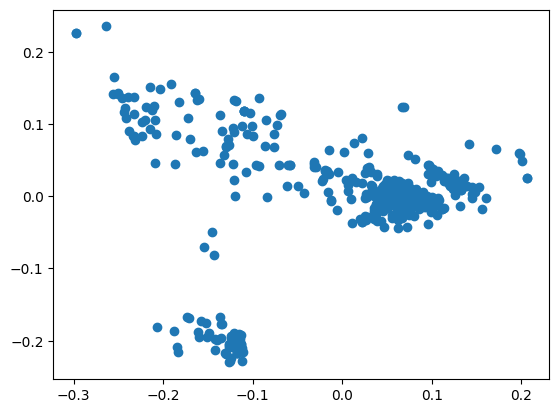

In [9]:
# On a nos embeddings pour chaque chunk (rappel: il y a 2176 chunk et 1024 dimensions à notre embedding).
# Maintenant, on aimerait pouvoir passer de ces embeddings à un truc qui soit un peu plus compréhensible
# pour un être humain. On veut pouvoir visualiser le dataset comme un graphe 2D sur lequel on aura été
# plotter l'embeddging de chacun de nos chunks (ce qui nous permettra de savoir combien de cluster on
# veut retrouver dans le dataset)
pca     = PCA(n_components=2)
emb_pca = pca.fit_transform(np.stack(df["embedding"]))

# maintenant on plot les données et on voit qu'il ya (à la grosse louche) 3 clusters
plt.scatter(emb_pca[:,0], emb_pca[:,1])

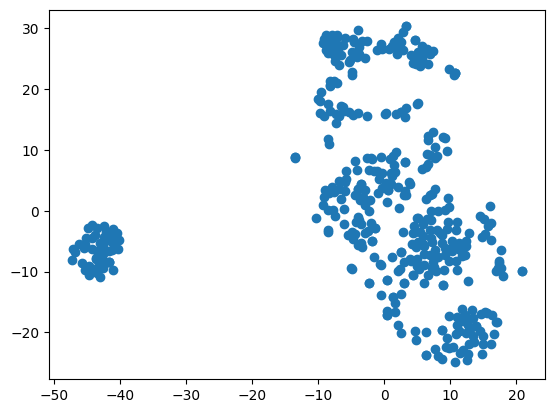

In [10]:
# Comme on sait que TSNE donne parfois une meilleure représentation des structures locales que PCA 
# pour un dataset donné, on effectue la même opération histoire de savoir s'il y a autre chose à
# y voir.
tsne     = TSNE(n_components=2)
emb_tsne = tsne.fit_transform(np.stack(df["embedding"]))

# et on plot pour voir ce que ca donne. Ici, on voit qu'il y a moyen de raffiner et compter
# 5 clusters différents (meme si c'est pas forcément super clear cut)
plt.scatter(emb_tsne[:,0], emb_tsne[:,1])

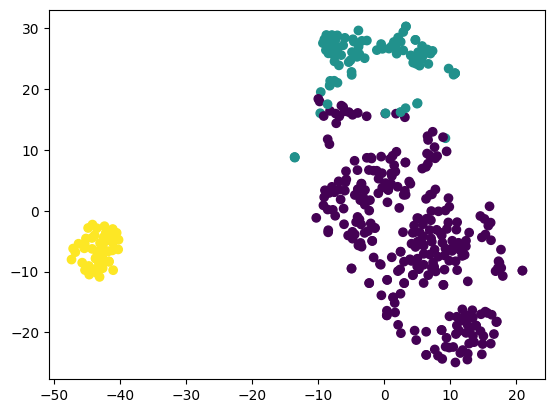

In [11]:
# Avec TSNE on voit qu'il y a en fait 9 clusters qu'on peut identifier. 
# On va essayer de les retrouver avec kmeans.
kmeans   = KMeans(n_clusters=3)
clusters = kmeans.fit(np.stack(df["embedding"]))
df["cluster"] = clusters.labels_

# on visualise le truc et on voit que ca colle pas mal.
plt.scatter(emb_tsne[:,0], emb_tsne[:,1], c=clusters.labels_)

In [12]:
# Je calcule simplement l'embedding moyen pour chacun des clusters qu'on a identifié.
# 
# L'expression est un peu compliquée, alors découpons là pour mieux comprendre
# ce que j'ai fait:
# 1. np.stack(l)     => convertit la liste d'embedding vers un seul ndarray qui sera la concaténation (empilement 
#                       vertical) de tous les ndarray dans la liste l.
# 2. np.mean(array)  => calcule le vecteur moyen pour les entrées dans array. Le parametre axis=0 est essentiel car
#                       sans ca, il calcule la moyenne de toutes les dimensions, pour tous les embeddings du tableau
#                       et il ne renvoie qu'une seule valeur. Ce n'est pas ce qu'on veut. Comme je l'ai fait ici, 
#                       ca fait la meme chose qu'un mean pooling.
# 3. np.linagl.norm  => normalise le vecteur pour qu'il ait une magnitude de 1.
#                       C'est nécessaire parce que comme on le voit plus haut, les embeddings produits par notre
#                       modèle sont normalisés. Donc si on veut pouvoir se comparer avec ces embeddings là, il faut
#                       aussi que nos embeddings moyens soient normalisés.
#                       Dans le contexte d'un RAG c'est aussi très important car ca permet de calculer la similarité
#                       cosinus sans avoir à re-normaliser les embeddings des chunks retrouvés dans la base de données.
#                       On peut alors simplement calculer le DOT product pour obtenir la meme valeur que la cosine sim.

def average_of_cluster(c):
    avg  = np.mean(np.stack(df[df['cluster']==c]['embedding']), axis=0)
    norm = np.linalg.norm(avg)
    return avg / norm

cluster_emb = np.array([ average_of_cluster(c) for c in sorted(df['cluster'].unique()) ])
cluster_emb.shape

(3, 768)

In [13]:
# Il ne reste maintenant plus qu'à trouver de quoi on parle au sein de ces clusters. Comme on a calculé l'embedding
# du centroide (=moyenne) de chaque cluster, il ne nous reste plus qu'à reprendre l'embedding de chacun des mots
# du vocabulaire puis essayer de trouver les 3 embeddings les plus proches de chacun de nos centroides.
# Une fois qu'on saura quel sont les tokens les plus proches, on pourra demander au tokenizer de les décoder pour
# pouvoir se faire une idée de ce dont il est question au sein des textes repris dans le cluster). 
# ==>> IMPORTANT <<===
# Ce genre de méthode permet de facilement 'miner' le contenu d'un corpus de textes pour se faire une idée des
# d'une catégorisation possible des sujets qui sont abordés dans les textes. Il est néanmoins important de 
# valider par après que ce qu'on a trouvé correspond effectivement à quelque chose d'utile pour les utilisateurs
# (== pour le business).

# Si on veut trouver l'embedding du token dont l'id est 17522, on fait simplement comme ca:
_17522 = base_model.embeddings.word_embeddings(torch.tensor([17522]).to(torch.int))    # equivaut a faire ca: basemodel.embedding.word_embedding[17522]
_17522.shape

torch.Size([1, 768])

In [14]:
# Nous ce qu'on veut, c'est connaitre l'embedding pour chacun des mots du vocabulaire. Ca tombe bien, c'est 
# facile a trouver: ce sont simplement les poids de la couche d'embeddings.
emb_vocab = base_model.embeddings.word_embeddings.weight
emb_vocab.shape

torch.Size([30500, 768])

In [15]:
# Comme on connait à la fois les embeddings de tous les mots du vocabulaire, et les embeddings des
# centroides de nos clusters, il ne reste plus qu'à trouver les mots dont les embeddings sont les
# plus proches de ceux des centroides. Ce qu'on fait en utilisant la cosine similarité.
#
# En faisant ceci, on obtient un tableau qui donne la similarité de chaque mot pour chaque cluster.
# il ne reste donc plus qu'à trouver les 3 (ou les 5 termes les plus proches). 
from sklearn.metrics.pairwise import cosine_similarity

similarity = cosine_similarity(cluster_emb, emb_vocab.detach().to(torch.float32).numpy())
similarity.shape

(3, 30500)

In [16]:
# Dans le vocabulaire, il y a plein de mots qui sont soit des tokens spéciaux/réservés
# soit des suffixes. Aucun de ces tokens ne nous intéressent car ils ne donnent pas une
# idée suffisamment claire de ce dont il est question dans le texte. On décide donc de
# s'en débarasser lorsqu'on fait notre comparaison.
def filter_cont(similarity, sentencepiece=True):
    vocab             = dict(tokenizer.vocab)
    vocab             = pd.DataFrame(list(vocab.keys()), columns=["text"], index=list(vocab.values()))
    vocab["decoded"]  = vocab.index.map(lambda x: tokenizer.decode([x]))
    vocab["is_start"] = vocab["decoded"].str.startswith(" ") if sentencepiece else ~(vocab["decoded"].str.startswith("##"))
    # on va maintenant filtrer les mots qui ne sont pas des 'débuts' de mot.
    mask = np.zeros_like(similarity, dtype=np.bool)
    for idx, row in vocab.iterrows():
        mask[:,idx] = not row.is_start
    return np.where(mask, 0, similarity)

similarity.shape

(3, 30500)

In [21]:
def topk(array, k=3):
    return np.argsort(array, axis=1)[:,-k:][::-1]

# Certains termes vont être repris dans absolument tous les clusters. Ils ne sont donc pas
# intéressants. On va donc les supprimer pour ne garder que ce qui apparait comme différent
# dans chaque cluster.
def drop_commons(meaning):
    meaning = [set(l) for l in meaning]
    inters  = set.intersection(*meaning)
    meaning = [ m - inters for m in meaning]
    return meaning

meaning = topk(filter_cont(similarity, sentencepiece=False), 20)
#meaning = topk(similarity, 10)
meaning = drop_commons(meaning)

# Et maintenant on imprime le contenu de ce qui est encore la.
for i,cluster in enumerate(meaning):
    print(f"* {i} => {list(map(lambda x: tokenizer.decode([x]), list(cluster)))}")

* 0 => ['oorzaak', 'overwegingen', 'geregeld', 'nieuw', 'betaalbaar', 'minder', 'gedaan', 'aangevangen', 'behoort', 'courant', 'doen', 'voorkomende', 'aankomst', 'varen', 'gevoelige', 'behoorde', 'voorkomt', 'gebeurtenissen']
* 1 => ['tijdelijk', 'twaalf', 'reizig', 'voorbijgaan', 'beur', 'vervallen', 'belasting', 'ƒ', 'tijdelijke', 'bijna', 'kast', 'overlijden', 'onvermijdelijk', 'sultan', 'grieven', 'verblijf', 'accijn', 'toenemende']
* 2 => ['toepasselijk', 'reeks', 'voorgrond', 'continuatie', 'zeer', 'minder', 'voorbijgaan', 'proef', 'vervallen', 'achteruit', 'ook', 'tract', 'overlijden', 'effect', 'griffier', 'voorkomt', 'grieven', 'toenemende']


### Resultats avec arch-be/brabant-xvii
* 0 => ['tijdelijk', 'twaalf', 'reizig', 'voorbijgaan', 'beur', 'vervallen', 'belasting', 'ƒ', 'tijdelijke', 'bijna', 'kast', 'overlijden', 'onvermijdelijk', 'sultan', 'grieven', 'verblijf', 'accijn', 'toenemende']
* 1 => ['toepasselijk', 'reeks', 'voorgrond', 'continuatie', 'zeer', 'minder', 'voorbijgaan', 'proef', 'vervallen', 'achteruit', 'ook', 'tract', 'overlijden', 'effect', 'griffier', 'voorkomt', 'grieven', 'toenemende']
* 2 => ['oorzaak', 'overwegingen', 'geregeld', 'nieuw', 'betaalbaar', 'minder', 'gedaan', 'aangevangen', 'behoort', 'courant', 'doen', 'voorkomende', 'aankomst', 'varen', 'gevoelige', 'behoorde', 'voorkomt', 'gebeurtenissen']

#### Hypothèses (à vérifier)
* Le groupe 0 pourrait parler d'histoires dans lesquels on a des voyageurs qui se font détrousser. Au cours des évènements, quelq'un se fait tuer ou presque. Le prince (sultan haha) exige des accises pour aller de l'avant.
* Le groupe 1 pourrait parler d'histoires dans lesquelles il s'agit essentiellement de régler des histoires de fiscales et/ou de succession et il faut adresser ses griefs au greffier.
* Le groupe 2 pourrait parler d'histoires impliquant des marins/bateliers.
  

In [28]:
# Alternative: max pooling (note: les résultats sont vraiment pourris avec)
def average_of_cluster(c):
    avg  = np.max(np.stack(df[df['cluster']==c]['embedding']), axis=0)
    norm = np.linalg.norm(avg)
    return avg / norm

cluster_emb = np.array([ average_of_cluster(c) for c in sorted(df['cluster'].unique()) ])
similarity  = cosine_similarity(cluster_emb, emb_vocab.detach().numpy())
meaning     = topk(similarity, 9)

for cluster in range(len(meaning)):
    print(f"* {cluster} => {tokenizer.convert_ids_to_tokens(meaning[cluster,:])}")

* 0 => ['die', 'het', 'dat', 'de', 'en', 'in', 'van', '.', ',']
* 1 => ['zeer', 'in', 'de', 'het', 'dat', 'en', 'van', '.', ',']
* 2 => ['de', 'dat', 'handen', 'zeer', 'van', 'doen', 'het', ',', '.']
